In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("public_survey.csv.xlsx")

clean = df.copy()
clean = clean.rename(columns={
    "Timestamp": "Response_Timestamp",
    "1. What is your age group? ": "Age_Group",
    "  2. How many hours do you spend on the internet daily?  ": "Daily_Internet_Usage",
    "  3. Do you read the \"Privacy Policy\" or \"Terms & Conditions\" before installing an app?  ": "Privacy_Policy_Reading",
    "  4. Have you ever seen ads for something you only talked about near your phone?  ": "Targeted_Ads_Experience",
    "  5. How worried are you about your personal data being sold or leaked?  ": "Data_Leak_Concern",
    "  6. How much do you trust big tech companies (like Google, Meta, TikTok) to protect your data?  ": "Big_Tech_Trust",
    "  7. Which type of personal data are you most afraid of losing or leaking?  ": "Most_Feared_Data",
    "  8. What do you do to protect your privacy online? (Choose all that apply)  ": "Privacy_Protection_Methods",
    "  9. Have you or someone you know ever had an account hacked or personal data leaked? Briefly describe what happened.  ": "Hacking_Experience",
    "  10. In your opinion, what should companies or governments do to better protect our personal data?  ": "Company_Government_Suggestions"
})
clean.insert(0, "Response_ID", range(1, len(clean) + 1))
print(clean.head())

clean.drop(columns=["Response_Timestamp"], inplace=True)
print(clean.columns)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

print(clean.columns.tolist())

print(clean.shape)
print(clean.columns)
print(clean.info())
print(clean.dtypes)
print("\nFIRST 5 ROWS:")
print(clean.head())
missing_percentage = (clean.isnull().sum())
print(missing_percentage)

   Response_ID      Response_Timestamp Age_Group Daily_Internet_Usage  \
0            1 2026-11-19 13:33:27.907   18 - 24          2 - 4 hours   
1            2 2026-11-19 13:35:54.388   18 - 24          2 - 4 hours   
2            3 2026-11-19 13:39:35.369   18 - 24          5 - 7 hours   
3            4 2026-11-19 13:40:57.313  Under 18    More than 7 hours   
4            5 2026-11-19 13:44:15.576  Under 18          5 - 7 hours   

  Privacy_Policy_Reading Targeted_Ads_Experience  Data_Leak_Concern  \
0              Sometimes                     Yes                  5   
1                 Rarely                Not Sure                  4   
2                  Never                     Yes                  4   
3              Sometimes                     Yes                  4   
4                 Rarely                     Yes                  5   

   Big_Tech_Trust              Most_Feared_Data  \
0               1          Passwords & Accounts   
1               4  Bank & Financ

In [2]:
display(clean.head().style.set_table_attributes('style="display:inline"'))

,Response_ID,Age_Group,Daily_Internet_Usage,Privacy_Policy_Reading,Targeted_Ads_Experience,Data_Leak_Concern,Big_Tech_Trust,Most_Feared_Data,Privacy_Protection_Methods,Hacking_Experience,Company_Government_Suggestions
0,1,18 - 24,2 - 4 hours,Sometimes,Yes,5,1,Passwords & Accounts,Use strong passwords,No,Make a Protective App Collect our personal data
1,2,18 - 24,2 - 4 hours,Rarely,Not Sure,4,4,Bank & Financial information,Use Two-Factor Authentication (2FA),Nah nothing happened yet,Just dont share it nga
2,3,18 - 24,5 - 7 hours,Never,Yes,4,2,Private photos & chats,Use Two-Factor Authentication (2FA),No,Never do the opposite to what they say
3,4,Under 18,More than 7 hours,Sometimes,Yes,4,3,Private photos & chats,Reject website cookies,I haven't experienced this personally but I've heard of people getting hacked through suspicious links It can steals their personal information and cause a lot of problems,"They should protect our personal information, use strong security systems and make sure hackers can't easily access our data"
4,5,Under 18,5 - 7 hours,Rarely,Yes,5,3,Passwords & Accounts,Reject website cookies,"Yes, someone I know has experienced an account being hacked. Their social media account was accessed without their permission, which made their personal information and private messages potentially exposed. This experience made me realize how important it is to use strong passwords, enable two-factor authentication, and be careful when sharing personal information online","In my opinion, companies and governments should take stronger measures to protect people's personal data by improving security systems, using encryption, and making sure personal information is not shared without permission. They should also raise awareness about online safety and take strict action against anyone who misuses or steals personal information."


In [3]:
for col in clean.select_dtypes(include="object").columns:
    print(f"\nColumn: {col}")
    print("Values with leading/trailing spaces:",
          clean[col].dropna().apply(
              lambda x: isinstance(x, str) and x != x.strip()
          ).sum())


Column: Age_Group
Values with leading/trailing spaces: 0

Column: Daily_Internet_Usage
Values with leading/trailing spaces: 0

Column: Privacy_Policy_Reading
Values with leading/trailing spaces: 0

Column: Targeted_Ads_Experience
Values with leading/trailing spaces: 0

Column: Most_Feared_Data
Values with leading/trailing spaces: 0

Column: Privacy_Protection_Methods
Values with leading/trailing spaces: 0

Column: Hacking_Experience
Values with leading/trailing spaces: 35

Column: Company_Government_Suggestions
Values with leading/trailing spaces: 59


In [4]:
text_columns = clean.select_dtypes(include="object").columns

for col in text_columns:
    clean[col] = clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [5]:
clean[text_columns] = clean[text_columns].replace(
    r"^\s*$", np.nan, regex=True
)

print(clean[text_columns].isnull().sum())

Age_Group                         0
Daily_Internet_Usage              0
Privacy_Policy_Reading            0
Targeted_Ads_Experience           0
Most_Feared_Data                  0
Privacy_Protection_Methods        0
Hacking_Experience                1
Company_Government_Suggestions    1
dtype: int64


In [6]:
duplicate_review = clean.loc[
    clean.duplicated(
        subset=clean.drop(columns=["Response_ID"]).columns,
        keep=False
    )
]
print("Duplicate Candidates:", len(duplicate_review))

Duplicate Candidates: 2


In [7]:
print("Original Shape:", df.shape)
print("Cleaned Shape:", clean.shape)

print("Original Responses:", len(df))
print("Cleaned Responses:", len(clean))

Original Shape: (166, 11)
Cleaned Shape: (166, 11)
Original Responses: 166
Cleaned Responses: 166


In [8]:
open_text_columns = [
    "Hacking_Experience",
    "Company_Government_Suggestions"
]
clean[open_text_columns] = clean[open_text_columns].fillna("Not Provided")

validation_missing = pd.DataFrame({
    "After_Cleaning": clean.isnull().sum()
})
print(validation_missing)

print("Duplicate IDs:", clean["Response_ID"].duplicated().sum())
print("Missing IDs:", clean["Response_ID"].isnull().sum())

print("Duplicate Response Candidates:",
      clean.drop(columns=["Response_ID"]).duplicated().sum())

                                After_Cleaning
Response_ID                                  0
Age_Group                                    0
Daily_Internet_Usage                         0
Privacy_Policy_Reading                       0
Targeted_Ads_Experience                      0
Data_Leak_Concern                            0
Big_Tech_Trust                               0
Most_Feared_Data                             0
Privacy_Protection_Methods                   0
Hacking_Experience                           0
Company_Government_Suggestions               0
Duplicate IDs: 0
Missing IDs: 0
Duplicate Response Candidates: 1


In [9]:
q9_ids = [21, 25, 26, 35, 36, 42, 45, 47, 57, 72, 95]

q10_ids = [
    13, 14, 21, 25, 26, 35, 36, 38, 42, 45, 47,
    48, 51, 55, 60, 68, 72, 92, 95, 104, 107, 114,
    115, 118, 132, 136, 143, 150, 153, 159, 166
]

clean.loc[
    clean["Response_ID"].isin(q9_ids),
    "Hacking_Experience"
] = "Off-topic Response"

clean.loc[
    clean["Response_ID"].isin(q10_ids),
    "Company_Government_Suggestions"
] = "Off-topic Response"
print(clean.head(15))

    Response_ID Age_Group Daily_Internet_Usage Privacy_Policy_Reading  \
0             1   18 - 24          2 - 4 hours              Sometimes   
1             2   18 - 24          2 - 4 hours                 Rarely   
2             3   18 - 24          5 - 7 hours                  Never   
3             4  Under 18    More than 7 hours              Sometimes   
4             5  Under 18          5 - 7 hours                 Rarely   
5             6   18 - 24    More than 7 hours                 Rarely   
6             7  Under 18          2 - 4 hours                  Never   
7             8   18 - 24          2 - 4 hours              Sometimes   
8             9   18 - 24          5 - 7 hours              Sometimes   
9            10  Under 18          5 - 7 hours              Sometimes   
10           11   18 - 24          2 - 4 hours                 Rarely   
11           12   18 - 24          5 - 7 hours                 Rarely   
12           13   18 - 24          5 - 7 hours     

In [10]:
print(clean[["Data_Leak_Concern", "Big_Tech_Trust"]].dtypes)

Data_Leak_Concern    int64
Big_Tech_Trust       int64
dtype: object


In [11]:
missing_before = df.isnull().sum()

missing_after = clean.isnull().sum()

print("Missing Values Before Cleaning:",missing_before)
print("missing after:", missing_after)

Missing Values Before Cleaning: Timestamp                                                                                                                  0
1. What is your age group?                                                                                                 0
  2. How many hours do you spend on the internet daily?                                                                    0
  3. Do you read the "Privacy Policy" or "Terms & Conditions" before installing an app?                                    0
  4. Have you ever seen ads for something you only talked about near your phone?                                           0
  5. How worried are you about your personal data being sold or leaked?                                                    0
  6. How much do you trust big tech companies (like Google, Meta, TikTok) to protect your data?                            0
  7. Which type of personal data are you most afraid of losing or leaking?                   

In [12]:
# 1. Descriptive Statistics
print("Numerical Analysis:")

display(
   clean[
        ["Data_Leak_Concern", "Big_Tech_Trust"]
    ].describe()
)

# 2. Age Group Analysis
print("\nAge Distribution:")

age_analysis = (
    clean["Age_Group"]
    .value_counts()
)

display(age_analysis)

# 3. Targeted Ads Analysis
print("\nTargeted Ads Experience:")

ads_analysis = (
    clean["Targeted_Ads_Experience"]
    .value_counts()
)

display(ads_analysis)

# 4. Privacy Policy Reading Analysis
print("\nPrivacy Policy Reading:")

policy_analysis = (
    clean["Privacy_Policy_Reading"]
    .value_counts()
)

display(policy_analysis)

# 5. Most Feared Personal Data
print("\nMost Feared Personal Data:")

feared_data_analysis = (
    clean["Most_Feared_Data"]
    .value_counts()
)

display(feared_data_analysis)

# 6. Privacy Protection Methods
print("\nPrivacy Protection Methods:")

method_analysis = (
   clean["Privacy_Protection_Methods"]
    .value_counts()
)

display(method_analysis)

# 7. Average Privacy Concern
print("\nAverage Data Leak Concern:")

print(
    clean["Data_Leak_Concern"].mean()
)

# 8. Average Big Tech Trust
print("\nAverage Big Tech Trust:")

print(
    clean["Big_Tech_Trust"].mean()
)

# 9. Analysis by Age Group
print("\nConcern and Trust by Age:")

age_comparison = (
    clean.groupby("Age_Group")
    .agg(
        Respondents=("Response_ID", "count"),
        Average_Concern=("Data_Leak_Concern", "mean"),
        Average_Trust=("Big_Tech_Trust", "mean")
    )
    .round(2)
)

display(age_comparison)

# 10. Targeted Ads by Age Group
print("\nTargeted Ads by Age:")

ads_by_age = pd.crosstab(
    clean["Age_Group"],
    clean["Targeted_Ads_Experience"],
    normalize="index"
).mul(100).round(2)

display(ads_by_age)

# 11. Privacy Concern vs Big Tech Trust
print("\nCorrelation Analysis:")

correlation = clean[
    ["Data_Leak_Concern", "Big_Tech_Trust"]
].corr()

display(correlation)

# 12. Recommendations Analysis
print("\nCompany and Government Recommendations:")

recommendations = (
    clean["Company_Government_Suggestions"]
    .value_counts()
)

display(recommendations)

Numerical Analysis:


,Data_Leak_Concern,Big_Tech_Trust
count,166.000000,166.000000
mean,3.740964,2.596386
std,1.175150,1.165041
min,1.000000,1.000000
25%,3.000000,2.000000
50%,4.000000,3.000000
75%,5.000000,3.000000
max,5.000000,5.000000



Age Distribution:


,count
Age_Group,
18 - 24,131
Under 18,19
35 - 44,10
25 - 34,4
45+,2



Targeted Ads Experience:


,count
Targeted_Ads_Experience,
Yes,139
Not Sure,19
No,8


... (10 outputs left out)


Correlation Analysis:


,Data_Leak_Concern,Big_Tech_Trust
Data_Leak_Concern,1.000000,0.148935
Big_Tech_Trust,0.148935,1.000000



Company and Government Recommendations:


,count
Company_Government_Suggestions,
Off-topic Response,31
.,3
I don't know,3
Idk,2
Yes,2
...,...
Companies should use strong security systems to prevent hackers from stealing information.,1
"Collect only the exact information needed for a service to function, and automatically delete it once that purpose ends",1
في كتير من الشركات دي هي البنفسها بتبيع الداتا ف هم محتاجين يكون في خصوصية اكتر من كده المفروض الداتا دي بس تتعطى لو الحكومة طلبت لاسباب قانونية لكن مينفعش الداتا تتباع لاي حد لمجرد الفلوس,1


In [13]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Response_ID                     166 non-null    int64 
 1   Age_Group                       166 non-null    object
 2   Daily_Internet_Usage            166 non-null    object
 3   Privacy_Policy_Reading          166 non-null    object
 4   Targeted_Ads_Experience         166 non-null    object
 5   Data_Leak_Concern               166 non-null    int64 
 6   Big_Tech_Trust                  166 non-null    int64 
 7   Most_Feared_Data                166 non-null    object
 8   Privacy_Protection_Methods      166 non-null    object
 9   Hacking_Experience              166 non-null    object
 10  Company_Government_Suggestions  166 non-null    object
dtypes: int64(3), object(8)
memory usage: 14.4+ KB


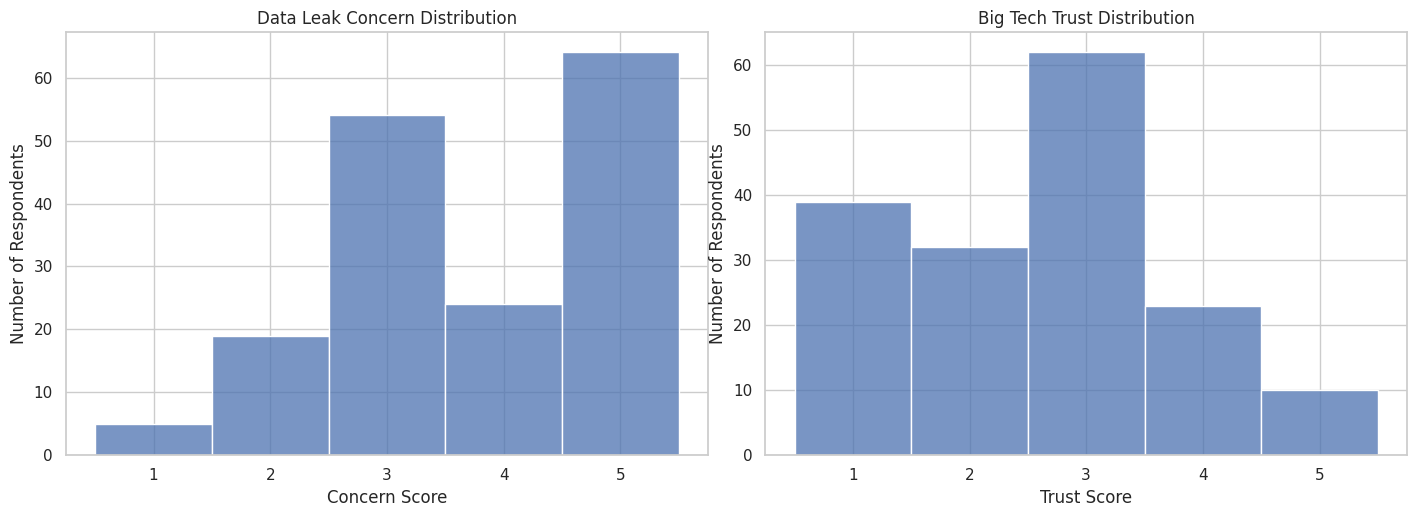

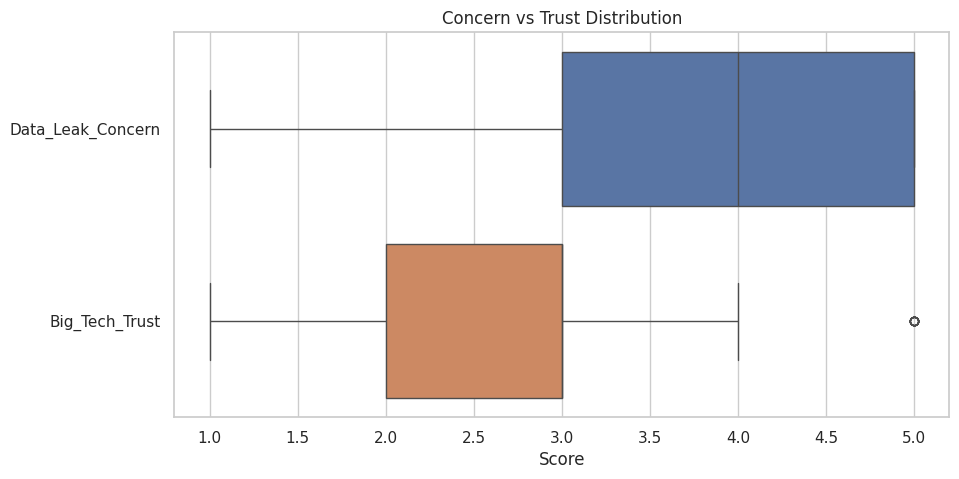

In [14]:
sns.set_theme(style="whitegrid")

# Set figure size
plt.rcParams["figure.figsize"] = (10, 6)

# Set font size
plt.rcParams["font.size"] = 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram Analysis
sns.histplot(
    data=clean,
    x="Data_Leak_Concern",
    bins=5,
    discrete=True,
    ax=axes[0]
)

axes[0].set_title("Data Leak Concern Distribution")
axes[0].set_xlabel("Concern Score")
axes[0].set_ylabel("Number of Respondents")

sns.histplot(
    data=clean,
    x="Big_Tech_Trust",
    bins=5,
    discrete=True,
    ax=axes[1]
)

axes[1].set_title("Big Tech Trust Distribution")
axes[1].set_xlabel("Trust Score")
axes[1].set_ylabel("Number of Respondents")

plt.tight_layout()
plt.show()


# 2. Boxplot Analysis

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=clean[
        ["Data_Leak_Concern", "Big_Tech_Trust"]
    ],
    orient="h"
)

plt.title("Concern vs Trust Distribution")
plt.xlabel("Score")
plt.show()

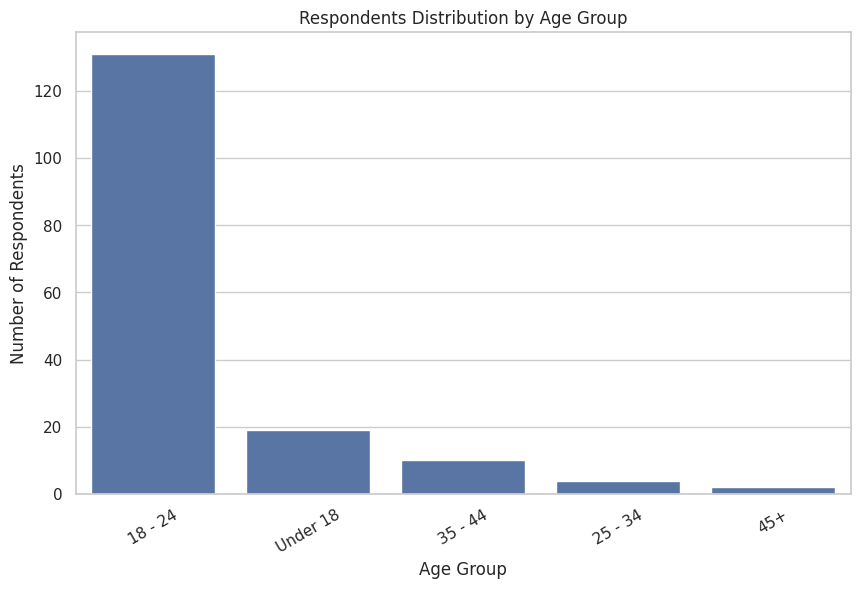

In [15]:
age_analysis = clean["Age_Group"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=age_analysis.index,
    y=age_analysis.values
)

plt.title("Respondents Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Respondents")

plt.xticks(rotation=30)

plt.show()

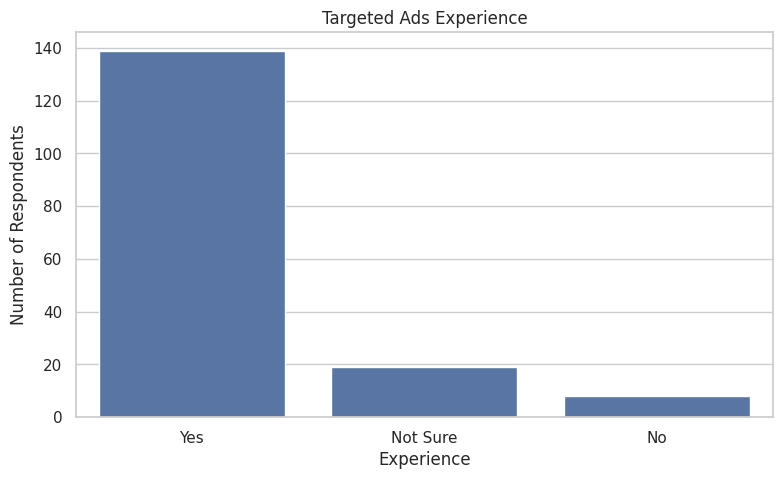

In [16]:
ads_analysis = clean["Targeted_Ads_Experience"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=ads_analysis.index,
    y=ads_analysis.values
)

plt.title("Targeted Ads Experience")
plt.xlabel("Experience")
plt.ylabel("Number of Respondents")

plt.show()

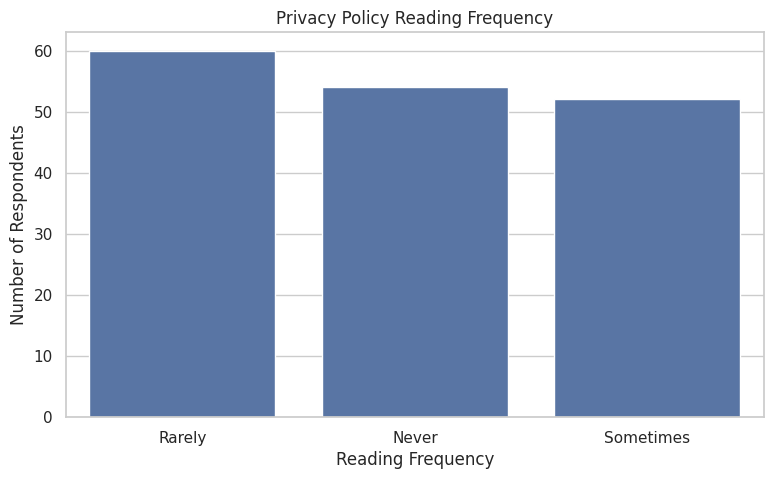

In [17]:
policy_analysis = clean["Privacy_Policy_Reading"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=policy_analysis.index,
    y=policy_analysis.values
)

plt.title("Privacy Policy Reading Frequency")
plt.xlabel("Reading Frequency")
plt.ylabel("Number of Respondents")

plt.show()

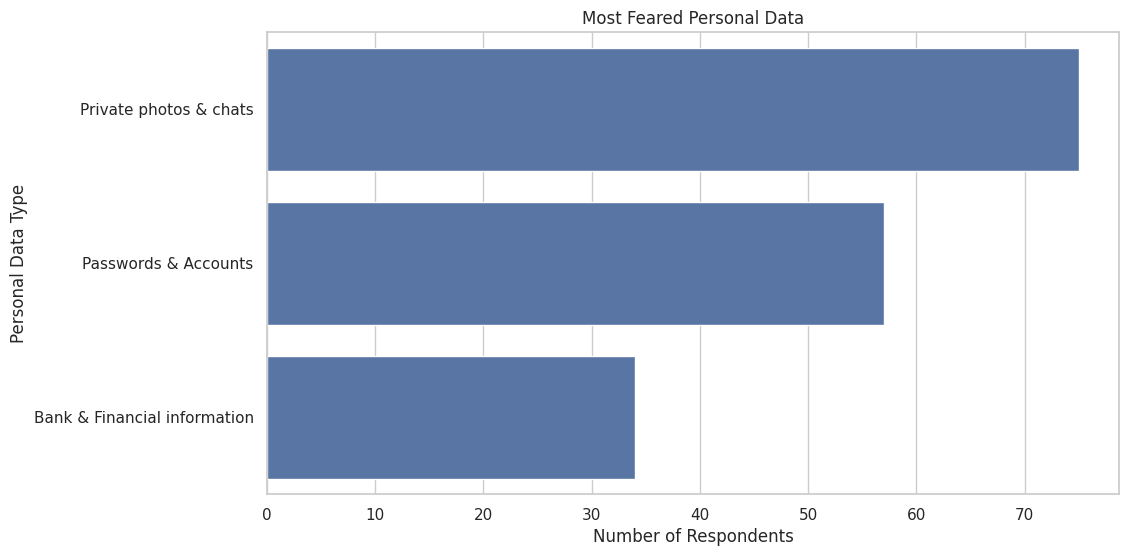

In [18]:
feared_data_analysis = clean["Most_Feared_Data"].value_counts()

plt.figure(figsize=(11, 6))

sns.barplot(
    y=feared_data_analysis.index,
    x=feared_data_analysis.values
)

plt.title("Most Feared Personal Data")
plt.xlabel("Number of Respondents")
plt.ylabel("Personal Data Type")

plt.show()

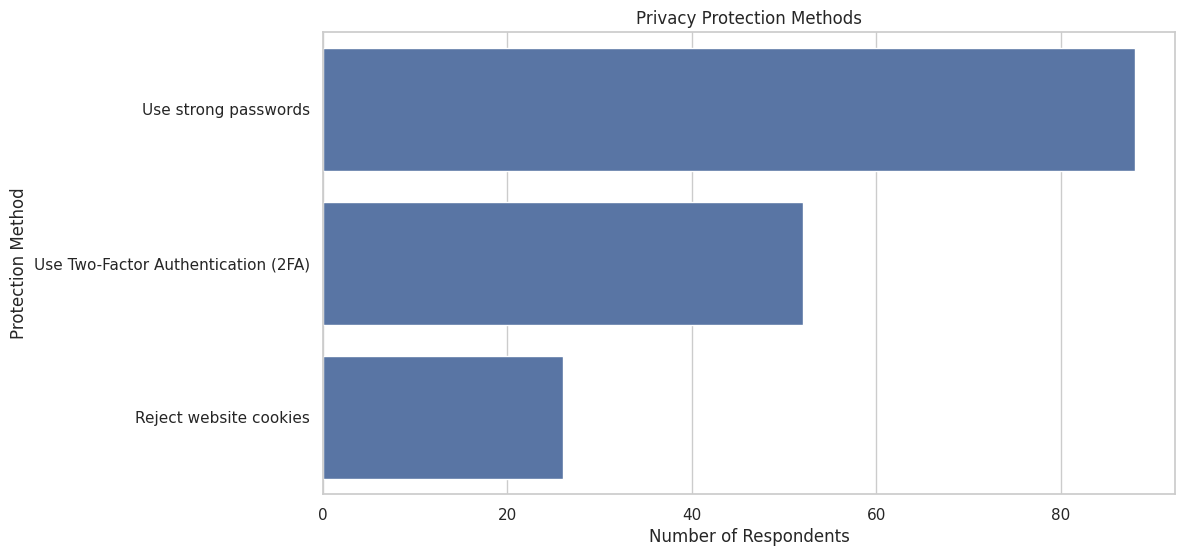

In [19]:
method_analysis = clean["Privacy_Protection_Methods"].value_counts()

plt.figure(figsize=(11, 6))

sns.barplot(
    y=method_analysis.index,
    x=method_analysis.values
)

plt.title("Privacy Protection Methods")
plt.xlabel("Number of Respondents")
plt.ylabel("Protection Method")

plt.show()

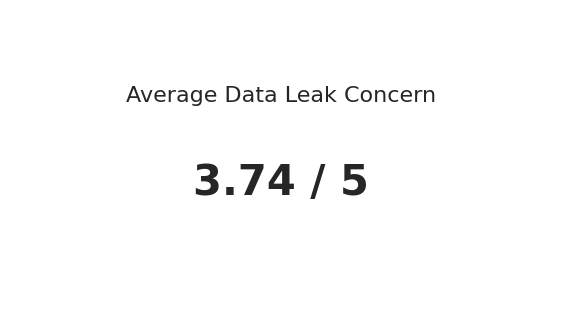

In [20]:
average_concern = clean["Data_Leak_Concern"].mean()

plt.figure(figsize=(7, 4))

plt.text(
    0.5, 0.7,
    "Average Data Leak Concern",
    ha="center",
    fontsize=16
)

plt.text(
    0.5, 0.4,
    f"{average_concern:.2f} / 5",
    ha="center",
    fontsize=30,
    fontweight="bold"
)

plt.axis("off")

plt.show()

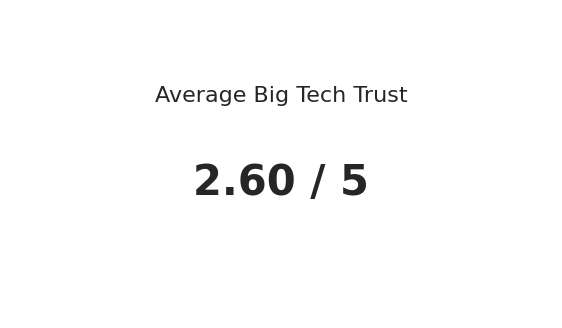

In [21]:
average_trust = clean["Big_Tech_Trust"].mean()

plt.figure(figsize=(7, 4))

plt.text(
    0.5, 0.7,
    "Average Big Tech Trust",
    ha="center",
    fontsize=16
)

plt.text(
    0.5, 0.4,
    f"{average_trust:.2f} / 5",
    ha="center",
    fontsize=30,
    fontweight="bold"
)

plt.axis("off")

plt.show()

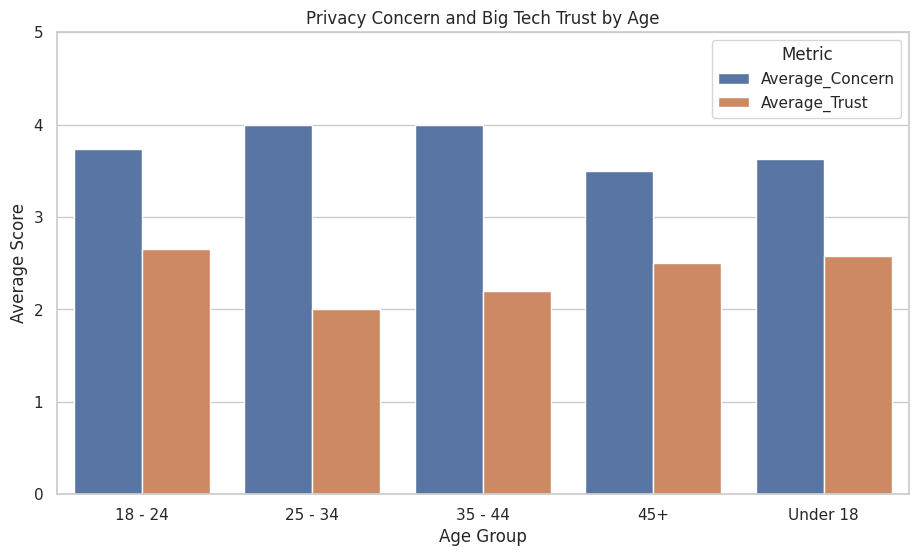

In [22]:
age_comparison = (
    clean.groupby("Age_Group")
    .agg(
        Average_Concern=("Data_Leak_Concern", "mean"),
        Average_Trust=("Big_Tech_Trust", "mean")
    )
    .reset_index()
)

age_comparison = age_comparison.melt(
    id_vars="Age_Group",
    var_name="Metric",
    value_name="Average_Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=age_comparison,
    x="Age_Group",
    y="Average_Score",
    hue="Metric"
)

plt.title("Privacy Concern and Big Tech Trust by Age")
plt.xlabel("Age Group")
plt.ylabel("Average Score")

plt.ylim(0, 5)

plt.legend(title="Metric")

plt.show()

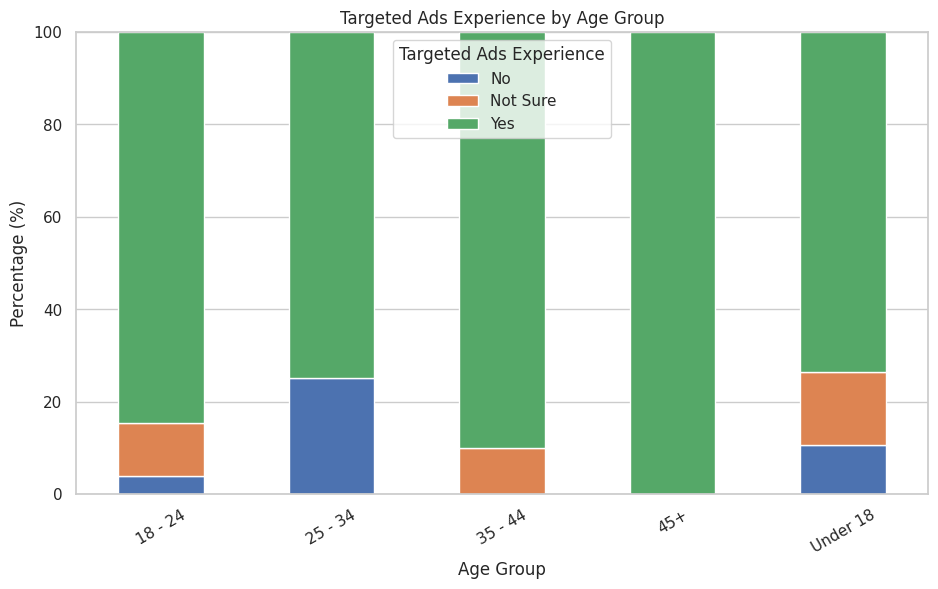

In [23]:
ads_by_age = pd.crosstab(
    clean["Age_Group"],
    clean["Targeted_Ads_Experience"],
    normalize="index"
).mul(100)

ads_by_age.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Targeted Ads Experience by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage (%)")

plt.ylim(0, 100)

plt.legend(title="Targeted Ads Experience")

plt.xticks(rotation=30)

plt.show()

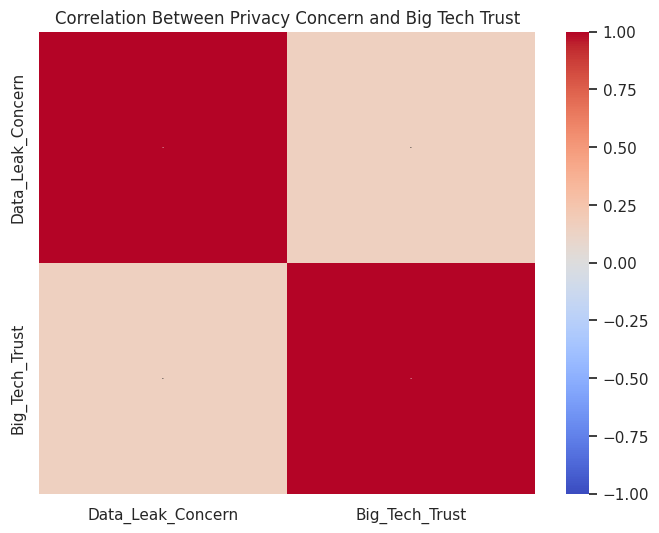

In [24]:
correlation = clean[
    ["Data_Leak_Concern", "Big_Tech_Trust"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Privacy Concern and Big Tech Trust")

plt.show()

In [25]:
display(clean)

,Response_ID,Age_Group,Daily_Internet_Usage,Privacy_Policy_Reading,Targeted_Ads_Experience,Data_Leak_Concern,Big_Tech_Trust,Most_Feared_Data,Privacy_Protection_Methods,Hacking_Experience,Company_Government_Suggestions
0,1,18 - 24,2 - 4 hours,Sometimes,Yes,5,1,Passwords & Accounts,Use strong passwords,No,Make a Protective App Collect our personal data
1,2,18 - 24,2 - 4 hours,Rarely,Not Sure,4,4,Bank & Financial information,Use Two-Factor Authentication (2FA),Nah nothing happened yet,Just dont share it nga
2,3,18 - 24,5 - 7 hours,Never,Yes,4,2,Private photos & chats,Use Two-Factor Authentication (2FA),No,Never do the opposite to what they say
3,4,Under 18,More than 7 hours,Sometimes,Yes,4,3,Private photos & chats,Reject website cookies,I haven't experienced this personally but I've heard of people getting hacked through suspicious links It can steals their personal information and cause a lot of problems,"They should protect our personal information, use strong security systems and make sure hackers can't easily access our data"
4,5,Under 18,5 - 7 hours,Rarely,Yes,5,3,Passwords & Accounts,Reject website cookies,"Yes, someone I know has experienced an account being hacked. Their social media account was accessed without their permission, which made their personal information and private messages potentially exposed. This experience made me realize how important it is to use strong passwords, enable two-factor authentication, and be careful when sharing personal information online","In my opinion, companies and governments should take stronger measures to protect people's personal data by improving security systems, using encryption, and making sure personal information is not shared without permission. They should also raise awareness about online safety and take strict action against anyone who misuses or steals personal information."
...,...,...,...,...,...,...,...,...,...,...,...
161,162,18 - 24,5 - 7 hours,Sometimes,Yes,2,3,Private photos & chats,Use strong passwords,"Yes, my cousin’s Facebook account git hacked once \nWe all blocked and reported the account","Collect only the exact information needed for a service to function, and automatically delete it once that purpose ends"
162,163,18 - 24,More than 7 hours,Never,Yes,3,3,Bank & Financial information,Use strong passwords,No,في كتير من الشركات دي هي البنفسها بتبيع الداتا ف هم محتاجين يكون في خصوصية اكتر من كده المفروض الداتا دي بس تتعطى لو الحكومة طلبت لاسباب قانونية لكن مينفعش الداتا تتباع لاي حد لمجرد الفلوس
163,164,18 - 24,2 - 4 hours,Rarely,Yes,4,1,Private photos & chats,Reject website cookies,"Yes, but I have no idea what happened exactly, no one close just people I know.","Stop using users as lab rats, and taking their personal data to sell or feed their models for “improvement”. More laws to hold them more accountable, as it seems they have great power, and freedom over us. Our privacy should be protected better than this."
164,165,Under 18,2 - 4 hours,Never,Yes,5,2,Passwords & Accounts,Reject website cookies,"No , I haven't got hacked or even someone I know",Keep our personal information safe🙃


In [26]:
clean.sample(5)

,Response_ID,Age_Group,Daily_Internet_Usage,Privacy_Policy_Reading,Targeted_Ads_Experience,Data_Leak_Concern,Big_Tech_Trust,Most_Feared_Data,Privacy_Protection_Methods,Hacking_Experience,Company_Government_Suggestions
135,136,25 - 34,More than 7 hours,Never,Yes,5,1,Passwords & Accounts,Use Two-Factor Authentication (2FA),Yup,Off-topic Response
107,108,18 - 24,5 - 7 hours,Rarely,Yes,5,2,Private photos & chats,Use strong passwords,no,idk
56,57,Under 18,2 - 4 hours,Never,Yes,1,1,Bank & Financial information,Use strong passwords,Off-topic Response,.
13,14,18 - 24,2 - 4 hours,Never,Yes,5,4,Passwords & Accounts,Use Two-Factor Authentication (2FA),no,Off-topic Response
38,39,18 - 24,5 - 7 hours,Never,Yes,4,2,Private photos & chats,Use strong passwords,Yes,Don't tell anyone any information


In [27]:
clean.Company_Government_Suggestions.sample(10)

,Company_Government_Suggestions
130,I guess provide more safety means and explain them to users.
12,Off-topic Response
163,"Stop using users as lab rats, and taking their personal data to sell or feed their models for “improvement”. More laws to hold them more accountable, as it seems they have great power, and freedom over us. Our privacy should be protected better than this."
132,Make for each person his own personal id
66,Increase protection for users
49,Save it in a hidden networks or storage
120,"Collect only the data that is truly instead of hoarding everythingMake privacy settings simple, clear, and easy to manage without hiding behind confusing menusUse strong encryption and make two-factor authentication standard to prevent account hacks"
9,idk
89,To send an alert if someone tried to hack my accounts and shut it down for them
13,Off-topic Response


In [28]:
clean.Hacking_Experience.sample(10)

,Hacking_Experience
111,Yes
105,no
33,No
155,"Nope, never."
47,No
100,I don't know
159,No
37,Yes.
87,No
101,Yes


In [29]:
import re

rules = {
    "Stronger Laws & Accountability": ["law", "legal", "regulation", "government", "penalty"],
    "Consent & Data Minimization": ["permission", "consent", "collect less", "minimum data"],
    "Transparency & User Control": ["transparent", "inform", "notify", "privacy settings"],
    "Privacy Awareness & Education": ["awareness", "educate", "education"],
    "Authentication & Access Control": ["password", "2fa", "otp", "authentication"],
    "Encryption": ["encrypt", "encryption"],
    "Preventing Misuse, Sale & Unauthorized Sharing": ["sell", "selling", "sharing", "don't share"],
    "Stronger Security & Data Protection": ["security", "protect", "protection", "hack", "safe"],
    "Technical Systems & Secure Infrastructure": ["app", "software", "system", "database"]
}

def categorize(answer):
    text = str(answer).lower().strip()

    if pd.isna(answer) or text in ["nan", ""]:
        return "Blank / No Response"

    if re.fullmatch(r"[\W_]+", text):
        return "No Meaningful Answer"

    if "i don't know" in text or "idk" in text:
        return "Unknown / No Suggestion"

    for theme, keywords in rules.items():
        if any(word in text for word in keywords):
            return theme

    return "Unclear / Off-topic"


clean["Recommendation_Theme"] = clean[
    "Company_Government_Suggestions"
].apply(categorize)

print(clean[[
    "Company_Government_Suggestions",
    "Recommendation_Theme"
]].head(10))

clean.to_excel("cleaned_data_with_categories.xlsx", index=False)

                                                                                                                                                                                                                                                                                                                                            Company_Government_Suggestions  \
0                                                                                                                                                                                                                                                                                                                          Make a Protective App Collect our personal data   
1                                                                                                                                                                                                                                                                           

In [30]:
clean.Recommendation_Theme.tail(10)

,Recommendation_Theme
156,Technical Systems & Secure Infrastructure
157,Technical Systems & Secure Infrastructure
158,Unclear / Off-topic
159,Stronger Security & Data Protection
160,Transparency & User Control
161,Transparency & User Control
162,Unclear / Off-topic
163,Stronger Laws & Accountability
164,Transparency & User Control
165,Unclear / Off-topic


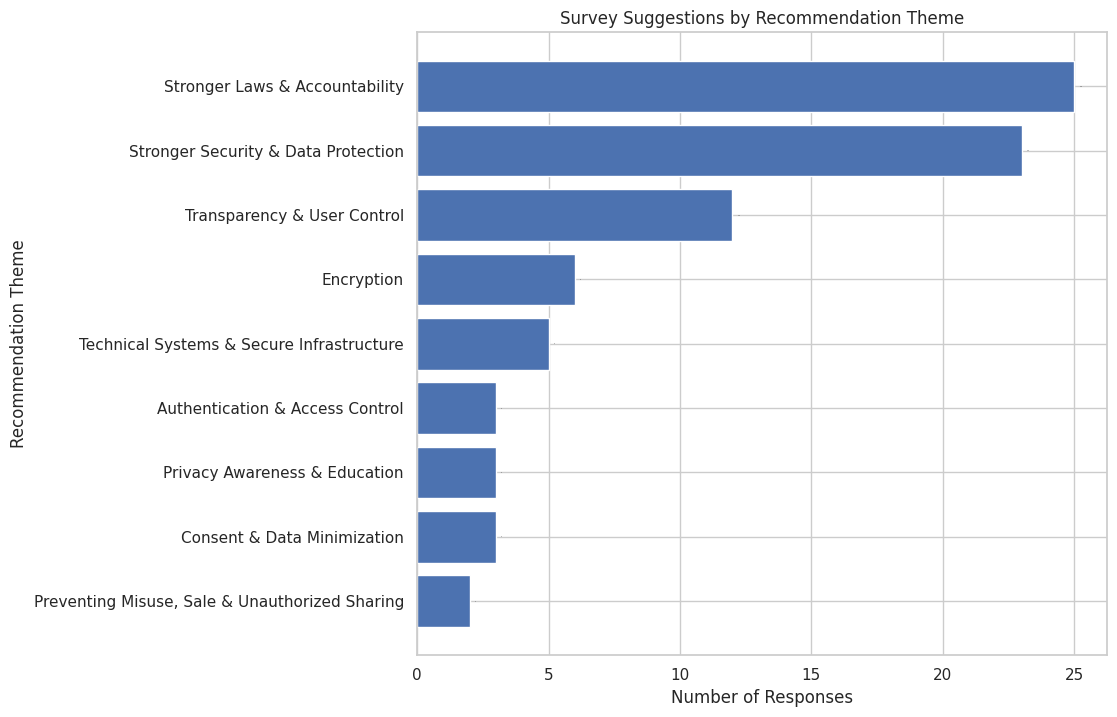

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

# Count each recommendation theme
theme_counts = clean["Recommendation_Theme"].value_counts()

# Exclude non-substantive responses
exclude = [
    "Unclear / Off-topic",
    "No Meaningful Answer",
    "Unknown / No Suggestion",
    "Blank / No Response"
]

theme_counts = theme_counts.drop(
    labels=exclude,
    errors="ignore"
)

# Sort values for horizontal bar chart
theme_counts = theme_counts.sort_values()

# Create visualization
plt.figure(figsize=(11, 7))

plt.barh(
    theme_counts.index,
    theme_counts.values
)

plt.xlabel("Number of Responses")
plt.ylabel("Recommendation Theme")
plt.title("Survey Suggestions by Recommendation Theme")

for i, value in enumerate(theme_counts.values):
    plt.text(value + 0.2, i, str(value), va="center")

plt.tight_layout()
plt.show()